# so sánh bốn hướng mlp

người thực hiện: như

Ngày phân tích: 21/11/2026

Trạng thái: phân tích kết quả đã lưu, không train mới.

Câu hỏi: tuning, cân bằng lớp và thay đổi kiến trúc/regularization có cải thiện kết quả ngoài mẫu so với cấu hình đối chứng không?

## dữ liệu và cách so sánh

Cùng physiological68, 6.189 cửa sổ và 15 người. Chỉ lấy các lượt chính seed 42, không chọn seed tốt nhất. EXP010 và EXP020 dùng nested LOSO với ba inner GroupKFold. EXP015 giữ tham số đã chọn của EXP010 và chỉ thêm ROS trên outer train. Mỗi độ đo được tính theo người rồi lấy mean và SD mẫu.

EXP006 ghi pandas 3.1.1; các lượt sau ghi pandas 3.1.0. Vì khác phiên bản, so sánh EXP010 với EXP006 là đối chiếu kết quả đã lưu, chưa phải thử nghiệm kiểm soát chỉ một yếu tố trong cùng môi trường. Ba hướng sau có cùng môi trường theo hồ sơ. Benchmark đã được dùng nhiều lần, chưa có test độc lập ngoài WESAD.

In [1]:
from pathlib import Path
import pandas as pd, json
candidates=[Path.cwd(),Path.cwd()/'wesad-stress-detection',*Path.cwd().parents,Path('C:\\Users\\LEGION\\Desktop\\github\\Machine-learning\\wesad-stress-detection'),Path('C:\\Users\\LEGION\\.codex\\worktrees\\nhu-exp-figures\\Machine-learning\\output\\mlp_comparison_20261121')]
root=next(p for p in candidates if (p/'reports/mlp_comparison_20261121').is_dir())
folder=root/'reports/mlp_comparison_20261121'
print('ngày phân tích: 21/11/2026')
print(pd.read_csv(folder/'summary.csv').to_string(index=False))

ngày phân tích: 21/11/2026
experiment       task  subjects  macro_f1_mean  macro_f1_sd  balanced_accuracy_mean  balanced_accuracy_sd
   EXP-006     binary        15       0.798599     0.184552                0.822476              0.167093
   EXP-006 multiclass        15       0.646155     0.114418                0.681516              0.105023
   EXP-010     binary        15       0.781909     0.186880                0.805156              0.168197
   EXP-010 multiclass        15       0.618670     0.133812                0.659146              0.110440
   EXP-015     binary        15       0.782632     0.197080                0.808506              0.172356
   EXP-015 multiclass        15       0.605639     0.142448                0.649838              0.113676
   EXP-020     binary        15       0.816369     0.175437                0.835633              0.164323
   EXP-020 multiclass        15       0.621062     0.114969                0.660917              0.103798


## kết quả và khác biệt theo người

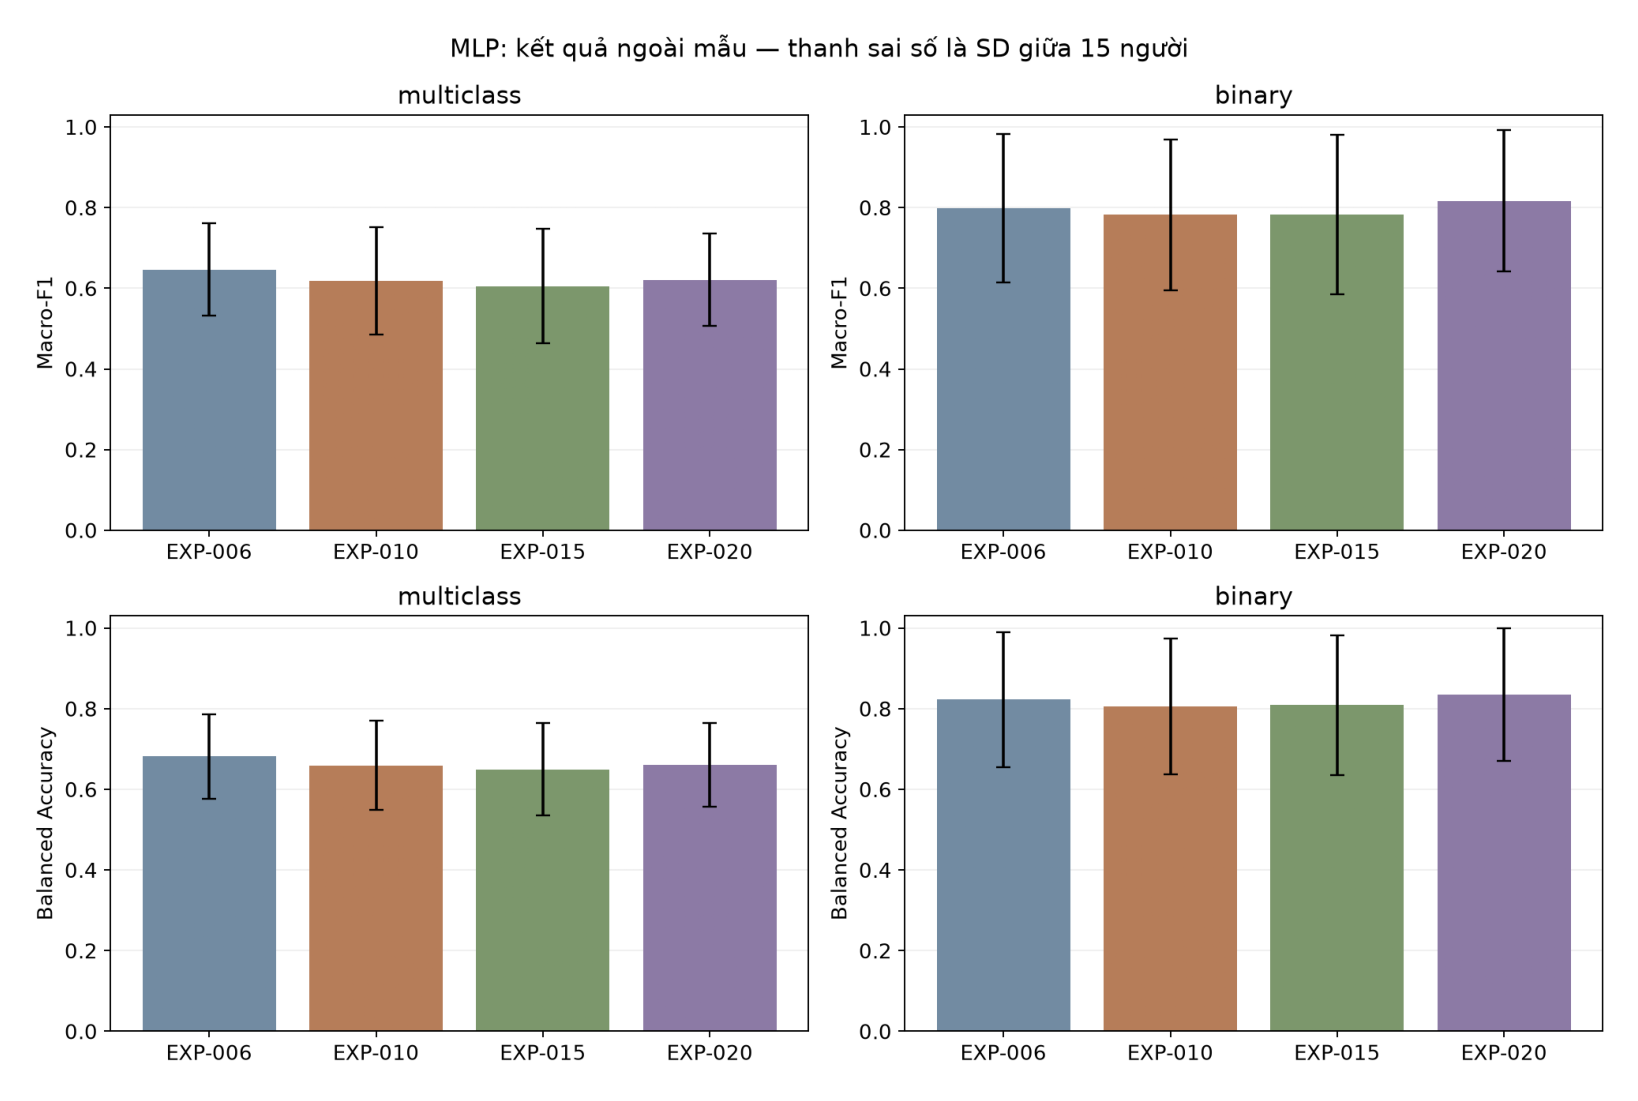

In [2]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(12,8))
plt.imshow(plt.imread(folder/'figures/mlp_four_experiments.png'))
plt.axis('off')
fig.tight_layout()

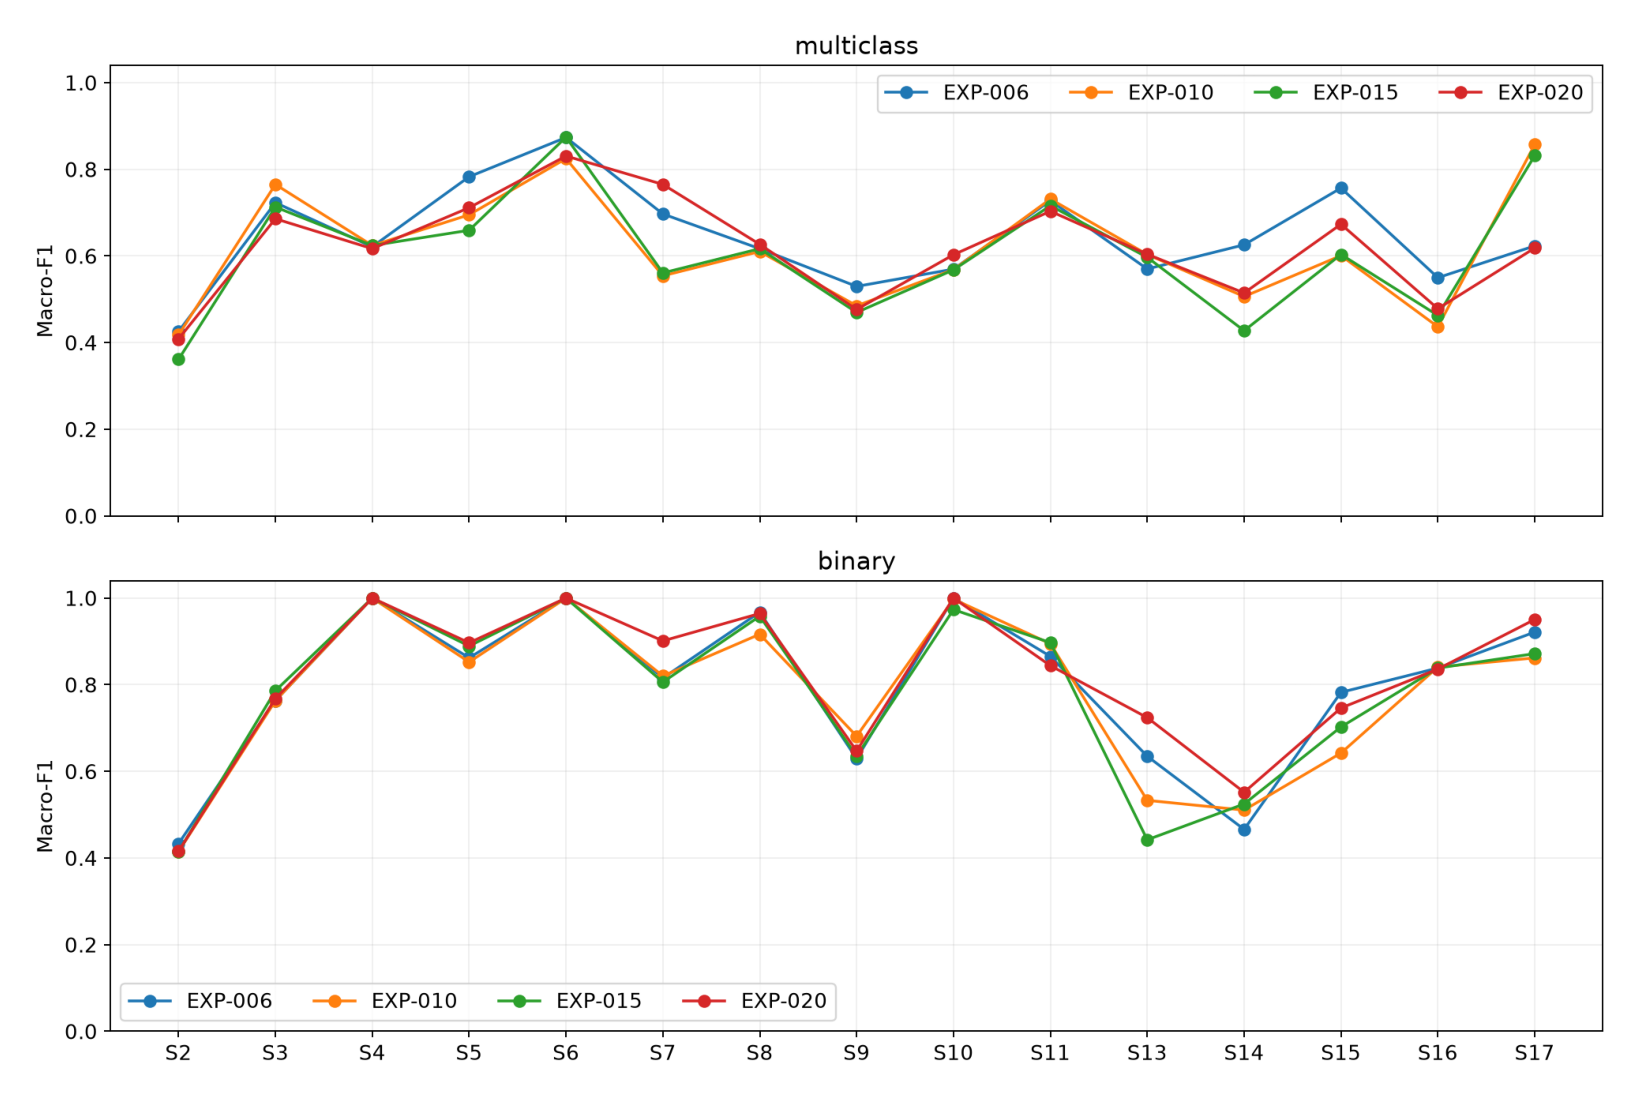

In [3]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(12,8))
plt.imshow(plt.imread(folder/'figures/mlp_subject_comparison.png'))
plt.axis('off')
fig.tight_layout()

## train và test

Điểm train lấy từ các lượt refit bổ sung đã lưu, không phải điểm inner validation. Đã đối chiếu điểm test với lượt đánh giá chính cho đủ 30 fold mỗi EXP. Không có đường loss test theo epoch trong các hồ sơ này.

experiment       task  train_macro_f1  test_macro_f1  train_balanced_accuracy  test_balanced_accuracy  macro_f1_gap
   EXP-006     binary             1.0       0.798599                      1.0                0.822476      0.201401
   EXP-006 multiclass             1.0       0.646155                      1.0                0.681516      0.353845
   EXP-010     binary             1.0       0.781909                      1.0                0.805156      0.218091
   EXP-010 multiclass             1.0       0.618670                      1.0                0.659146      0.381330
   EXP-015     binary             1.0       0.782632                      1.0                0.808506      0.217368
   EXP-015 multiclass             1.0       0.605639                      1.0                0.649838      0.394361
   EXP-020     binary             1.0       0.816369                      1.0                0.835633      0.183631
   EXP-020 multiclass             1.0       0.621062                    

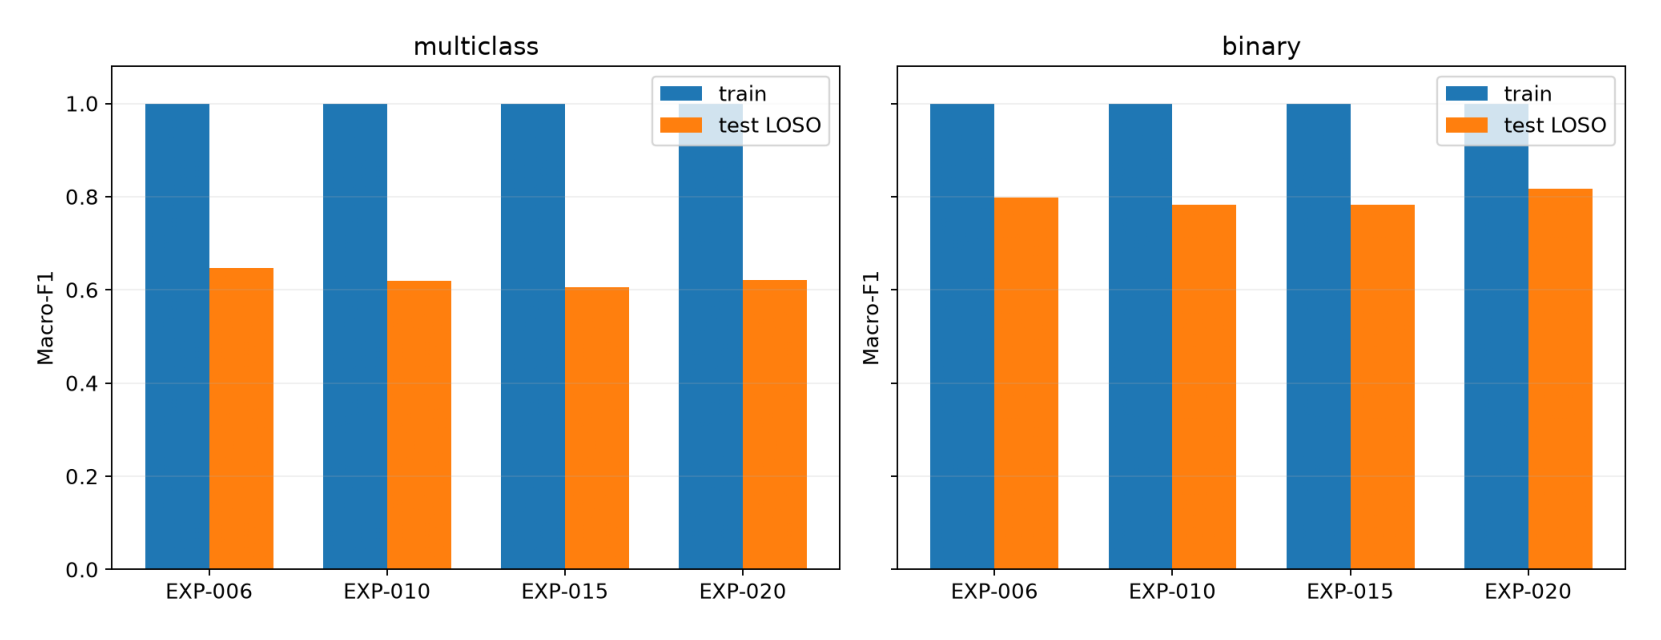

In [4]:
print(pd.read_csv(folder/'train_test_summary.csv').to_string(index=False))
fig=plt.figure(figsize=(12,5))
plt.imshow(plt.imread(folder/'figures/mlp_train_test_comparison.png'))
plt.axis('off')
fig.tight_layout()

## hội tụ và đối chứng

In [5]:
print(pd.read_csv(folder/'convergence.csv').to_string(index=False))
pairs=pd.read_csv(folder/'paired_differences.csv')
print(pairs.groupby(['experiment','reference','task'])[['delta_macro_f1','delta_balanced_accuracy']].mean().to_string())

experiment       task  mean_epochs  max_epochs  folds_at_200  warning_count
   EXP-006     binary    41.266667          43             0              0
   EXP-006 multiclass    46.666667          48             0              0
   EXP-010     binary    22.400000          58             0              0
   EXP-010 multiclass    46.600000          67             0              0
   EXP-015     binary    20.133333          48             0              0
   EXP-015 multiclass    36.533333          52             0              0
   EXP-020     binary    78.000000         100             0              0
   EXP-020 multiclass    63.466667         119             0              0
                                 delta_macro_f1  delta_balanced_accuracy
experiment reference task                                               
EXP-010    EXP-006   binary           -0.016690                -0.017320
                     multiclass       -0.027485                -0.022370
EXP-015    EXP-010   bin

## nhận xét tham khảo

Ở ba lớp, EXP006 có Macro-F1 cao nhất trong bốn lượt chính đã lưu. Tuning trong EXP010 không làm điểm trung bình tăng so với baseline. Khi thêm ROS ở EXP015, Macro-F1 ba lớp giảm so với EXP010, còn nhị phân chỉ tăng nhẹ.

EXP020 cải thiện Macro-F1 so với EXP010, rõ hơn ở nhị phân, nhưng ba lớp vẫn thấp hơn EXP006. Điểm train của các lượt refit đều đạt 1 trong khi test thấp hơn, cho thấy khoảng cách train/test còn lớn. Đạt điều kiện dừng và không có cảnh báo không có nghĩa mô hình đã tổng quát hóa tốt.

Lượt kiểm tra seed 43/44 của EXP020 ngày 20/11 cho thấy nhị phân nhạy với seed hơn ba lớp. Không đổi kết quả chính sang seed 44 chỉ vì điểm cao hơn.

Đây mới là đối chiếu MLP. Chưa kết luận MLP là mô hình tốt nhất của nhóm và chưa chốt mô hình demo từ bảng này. Có thể tiếp tục thử môi trường đồng nhất cho EXP006/010 hoặc tách ảnh hưởng kiến trúc và alpha trong inner CV nếu nhóm cần nghiên cứu sâu hơn.